# Organization Business Analytics Dashboard

## Project Overview

This project performs end-to-end business data analysis using Python, Pandas, NumPy, and Matplotlib.

The organization dataset is stored in an Excel workbook containing multiple interconnected sheets representing different business functions.

The objective is to analyze the complete organization from different perspectives including:

- Departments
- Employees
- Products
- Customers
- Orders
- Marketing
- Finance
- Attendance
- Customer Support
- Projects

The analysis will transform raw organizational data into meaningful business insights, Key Performance Indicators (KPIs), and visualizations.

## Project Objectives

1. Load data from multiple Excel sheets.
2. Understand the structure of each dataset.
3. Inspect data types and data quality.
4. Identify missing values and duplicate records.
5. Clean and standardize the datasets.
6. Connect related datasets using common identifiers.
7. Perform exploratory data analysis using Pandas.
8. Calculate important business KPIs.
9. Analyze sales, finance, employees, customers, marketing, support, and projects.
10. Create visualizations using Matplotlib.
11. Build an executive-level dashboard.
12. Generate business insights and recommendations.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook
- Microsoft Excel

## Dataset

File: `Organization_Business_Data.xlsx`

# Dataset Relationship Flow

The Excel workbook contains 10 interconnected datasets.

```text
                         DEPARTMENTS
                            │
                          DeptID
                            │
          ┌─────────────────┼─────────────────┐
          │                 │                 │
          ▼                 ▼                 ▼
      EMPLOYEES          FINANCE          PROJECTS
          │
        EmpID
          │
     ┌────┴─────┐
     ▼          ▼
 ATTENDANCE   SUPPORT_TICKETS
                  │
          ┌───────┴────────┐
          │                │
     CustomerID        ProductID
          │                │
          ▼                ▼
      CUSTOMERS         PRODUCTS
          │                │
          └───────┬────────┘
                  ▼
                ORDERS

DEPARTMENTS
     │
   DeptID
     ▼
MARKETING_CAMPAIGNS



| Relationship                | Key          |
| --------------------------- | ------------ |
| Departments → Employees     | `DeptID`     |
| Departments → Finance       | `DeptID`     |
| Departments → Projects      | `DeptID`     |
| Departments → Marketing     | `DeptID`     |
| Employees → Attendance      | `EmpID`      |
| Employees → Support Tickets | `EmpID`      |
| Customers → Orders          | `CustomerID` |
| Products → Orders           | `ProductID`  |
| Customers → Support Tickets | `CustomerID` |
| Products → Support Tickets  | `ProductID`  |


## 1. Importing Required Libraries

Python libraries provide ready-made functionality for data analysis and visualization.

### Pandas

Pandas is used for:
- Reading Excel files
- Creating DataFrames
- Data cleaning
- Filtering
- Grouping
- Aggregation
- Merging datasets

### NumPy

NumPy is used for numerical calculations and mathematical operations.

### Matplotlib

Matplotlib is used to create charts and visualizations that help communicate business insights.

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Loading the Excel Workbook

The organization data is stored in a single Excel workbook containing multiple sheets.

We first load the workbook and identify all available sheets before performing analysis.

In [163]:
file_path = "Organization_Business_Data.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Available Sheets:")
print(excel_file.sheet_names)

Available Sheets:
['Departments', 'Employees', 'Products', 'Customers', 'Orders', 'Marketing_Campaigns', 'Finance_Monthly', 'Attendance_Monthly', 'Support_Tickets', 'Projects']


## 3. Loading Individual Datasets

Each Excel sheet represents a different business function.

We load each sheet into a separate Pandas DataFrame so that the datasets can be independently inspected, cleaned, analyzed, and later connected using common identifiers.

In [164]:
departments = pd.read_excel(file_path, sheet_name="Departments")
employees = pd.read_excel(file_path, sheet_name="Employees")
products = pd.read_excel(file_path, sheet_name="Products")
customers = pd.read_excel(file_path, sheet_name="Customers")
orders = pd.read_excel(file_path, sheet_name="Orders")
marketing = pd.read_excel(file_path, sheet_name="Marketing_Campaigns")
finance = pd.read_excel(file_path, sheet_name="Finance_Monthly")
attendance = pd.read_excel(file_path, sheet_name="Attendance_Monthly")
support = pd.read_excel(file_path, sheet_name="Support_Tickets")
projects = pd.read_excel(file_path, sheet_name="Projects")

## 4. Initial Data Inspection

Before performing analysis, a Data Scientist must understand the structure of the data.

We inspect:

- First records
- Last records
- Number of rows and columns
- Column names
- Data types
- Statistical summary
- Missing values
- Duplicate records

In [165]:
employees.head()

,EmpID,FullName,Gender,Age,DeptID,JobTitle,RoleLevel,HireDate,City,State,Email,AnnualSalary_INR,AnnualBonus_INR,PerformanceRating,EmploymentStatus,ResignDate,WorkMode,ManagerID
0,E0001,Kiara Sharma,female,37.0,D02,Marketing Executive,Senior,2026-03-26,Bengaluru,Karnataka,kiara.sharma1@nimbustech.com,"INR 1,342,417",33675,2.7,Active,NaN,Hybrid,E0075
1,E0002,Naveen Joshi,Female,36.0,D03,QA Engineer,Lead,2014-02-23,Hyderabad,Telangana,naveen.joshi2@nimbustech.com,1943143,144648,3.0,Resigned,2016-07-11,Onsite,E0191
2,E0003,Deepak Nair,Female,44.0,D04,Support Executive,Senior,01/10/2026,Bengaluru,Karnataka,deepak.nair3@nimbustech.com,1296922,42290,NaN,Active,NaN,Remote,E0204
3,E0004,Sunil Das,Male,26.0,D01,Sales Manager,Senior,16-10-2015,Mumbai,Maharashtra,sunil.das4@nimbustech.com,1005907,81298,3.6,Active,NaN,Onsite,E0020
4,E0005,AMIT REDDY,female,26.0,D04,Senior Support Executive,Mid,2019-06-29,Hyderabad,Telangana,amit.reddy5@nimbustech.com,742357,59918,4.8,Active,NaN,Hybrid,E0016


In [166]:
orders.head()

,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
0,O02799,2022-04-29,C0255,P009,E0174,1,19960.0,0,19960.0,West,Credit Card,Completed,2022-05-08
1,O00043,2025-04-12,C0017,P021,E0004,2,11090.0,0,22180.0,South,Bank Transfer,Completed,2025-04-21
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,UPI,Completed,2024-07-26
3,O02114,2024-09-28,C0050,P009,E0043,1,19960.0,5,18962.0,West,Bank Transfer,Cancelled,NaN
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,Net Banking,Completed,2024-08-21


In [167]:
orders.tail()

,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
6020,O03322,2025-07-07,C0178,P007,E0090,2,3080.0,0,6160.0,North,Bank Transfer,Completed,2025-07-11
6021,O03008,2026-06-18,C0174,P021,E0004,2,11090.0,0,22180.0,Central,Cheque,Completed,2026-06-24
6022,O00952,2024-03-31,C0565,P021,E0043,1,11090.0,10,9981.0,Central,UPI,Cancelled,NaN
6023,O01296,2026-05-12,C0134,P006,E0095,1,12900.0,5,12255.0,North,Cheque,completed,2026-05-15
6024,O05834,2019-01-27,C0112,P019,E0103,3,8290.0,0,24870.0,East,Cheque,Completed,2019-02-05


In [168]:
print("Orders Shape:", orders.shape)
print("Employees Shape:", employees.shape)
print("Customers Shape:", customers.shape)

Orders Shape: (6025, 13)
Employees Shape: (226, 18)
Customers Shape: (610, 8)


In [169]:
datasets = {
    "Departments": departments,
    "Employees": employees,
    "Products": products,
    "Customers": customers,
    "Orders": orders,
    "Marketing": marketing,
    "Finance": finance,
    "Attendance": attendance,
    "Support": support,
    "Projects": projects
}

for name, df in datasets.items():
    print("=" * 60)
    print(name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

Departments
Shape: (10, 5)
Columns: ['DeptID', 'DeptName', 'Location', 'AnnualBudget_INR', 'YearFounded']
Employees
Shape: (226, 18)
Columns: ['EmpID', 'FullName', 'Gender', 'Age', 'DeptID', 'JobTitle', 'RoleLevel', 'HireDate', 'City', 'State', 'Email', 'AnnualSalary_INR', 'AnnualBonus_INR', 'PerformanceRating', 'EmploymentStatus', 'ResignDate', 'WorkMode', 'ManagerID']
Products
Shape: (22, 8)
Columns: ['ProductID', 'ProductName', 'Category', 'LaunchDate', 'UnitCost_INR', 'UnitPrice_INR', 'StockQuantity', 'Supplier']
Customers
Shape: (610, 8)
Columns: ['CustomerID', 'CustomerName', 'Segment', 'Industry', 'Region', 'City', 'State', 'JoinDate']
Orders
Shape: (6025, 13)
Columns: ['OrderID', 'OrderDate', 'CustomerID', 'ProductID', 'EmployeeID', 'Quantity', 'UnitPrice_INR', 'Discount_Pct', 'TotalAmount_INR', 'Region', 'PaymentMethod', 'OrderStatus', 'DeliveryDate']
Marketing
Shape: (40, 10)
Columns: ['CampaignID', 'CampaignName', 'Channel', 'StartDate', 'EndDate', 'Budget_INR', 'DeptID', 'L

### Data Types and Structure

The `info()` function provides information about:

- Column names
- Number of non-null values
- Data types
- Memory usage

Understanding data types is important before performing calculations.

In [170]:
orders.info()
employees.info()
customers.info()
finance.info()

<class 'pandas.DataFrame'>
RangeIndex: 6025 entries, 0 to 6024
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          6025 non-null   str    
 1   OrderDate        6025 non-null   str    
 2   CustomerID       6025 non-null   str    
 3   ProductID        6025 non-null   str    
 4   EmployeeID       6025 non-null   str    
 5   Quantity         6025 non-null   int64  
 6   UnitPrice_INR    6025 non-null   float64
 7   Discount_Pct     6025 non-null   int64  
 8   TotalAmount_INR  6025 non-null   str    
 9   Region           6025 non-null   str    
 10  PaymentMethod    5717 non-null   str    
 11  OrderStatus      6025 non-null   str    
 12  DeliveryDate     4780 non-null   str    
dtypes: float64(1), int64(2), str(10)
memory usage: 612.0 KB
<class 'pandas.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------

### Statistical Summary

The `describe()` function provides statistical information for numerical columns.

It includes:

- Count
- Mean
- Standard deviation
- Minimum
- 25th percentile
- Median
- 75th percentile
- Maximum

In [171]:
orders.describe()


,Quantity,UnitPrice_INR,Discount_Pct
count,6025.000000,6025.000000,6025.000000
mean,2.310041,28228.147718,5.291286
std,1.985457,19971.184800,6.056449
min,-5.000000,3080.000000,0.000000
25%,1.000000,11090.000000,0.000000
50%,2.000000,23800.000000,5.000000
75%,3.000000,44810.000000,10.000000
max,10.000000,74070.000000,20.000000


In [172]:
employees.describe()

,Age,AnnualBonus_INR,PerformanceRating
count,216.000000,226.000000,207.000000
mean,43.893519,104735.216814,3.655556
std,44.328192,88811.874054,0.586048
min,22.000000,10797.000000,2.100000
25%,29.000000,45529.750000,3.300000
50%,37.500000,72576.500000,3.700000
75%,50.000000,132644.250000,4.000000
max,440.000000,458741.000000,4.800000


### Selecting Columns

Pandas allows us to select one or more columns from a DataFrame.

Selecting relevant columns makes analysis easier and allows us to focus on specific business information.

In [173]:
orders["TotalAmount_INR"]

0        19960.0
1        22180.0
2        65952.0
3        18962.0
4       141322.0
          ...   
6020      6160.0
6021     22180.0
6022      9981.0
6023     12255.0
6024     24870.0
Name: TotalAmount_INR, Length: 6025, dtype: str

In [174]:
orders[["OrderID", "CustomerID", "TotalAmount_INR"]]

,OrderID,CustomerID,TotalAmount_INR
0,O02799,C0255,19960.0
1,O00043,C0017,22180.0
2,O03169,C0447,65952.0
3,O02114,C0050,18962.0
4,O02646,C0021,141322.0
...,...,...,...
6020,O03322,C0178,6160.0
6021,O03008,C0174,22180.0
6022,O00952,C0565,9981.0
6023,O01296,C0134,12255.0


In [234]:
orders[["OrderID", "OrderDate", "CustomerID", "ProductID", "TotalAmount_INR"]].head()

,OrderID,OrderDate,CustomerID,ProductID,TotalAmount_INR
0,O02799,2022-04-29,C0255,P009,19960.0
1,O00043,2025-04-12,C0017,P021,22180.0
2,O03169,2024-07-22,C0447,P022,65952.0
3,O02114,2024-09-28,C0050,P009,18962.0
4,O02646,2024-08-12,C0021,P012,141322.0


### Filtering Rows

Filtering allows us to select records that satisfy a specific condition.

For example, we can find orders above ₹100,000.

In [176]:
orders[orders["UnitPrice_INR"] > 10000].head()

,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
0,O02799,2022-04-29,C0255,P009,E0174,1,19960.0,0,19960.0,West,Credit Card,Completed,2022-05-08
1,O00043,2025-04-12,C0017,P021,E0004,2,11090.0,0,22180.0,South,Bank Transfer,Completed,2025-04-21
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,UPI,Completed,2024-07-26
3,O02114,2024-09-28,C0050,P009,E0043,1,19960.0,5,18962.0,West,Bank Transfer,Cancelled,NaN
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,Net Banking,Completed,2024-08-21


In [177]:
employees[employees["EmploymentStatus"] == "Active"].head()

,EmpID,FullName,Gender,Age,DeptID,JobTitle,RoleLevel,HireDate,City,State,Email,AnnualSalary_INR,AnnualBonus_INR,PerformanceRating,EmploymentStatus,ResignDate,WorkMode,ManagerID
0,E0001,Kiara Sharma,female,37.0,D02,Marketing Executive,Senior,2026-03-26,Bengaluru,Karnataka,kiara.sharma1@nimbustech.com,"INR 1,342,417",33675,2.7,Active,NaN,Hybrid,E0075
2,E0003,Deepak Nair,Female,44.0,D04,Support Executive,Senior,01/10/2026,Bengaluru,Karnataka,deepak.nair3@nimbustech.com,1296922,42290,NaN,Active,NaN,Remote,E0204
3,E0004,Sunil Das,Male,26.0,D01,Sales Manager,Senior,16-10-2015,Mumbai,Maharashtra,sunil.das4@nimbustech.com,1005907,81298,3.6,Active,NaN,Onsite,E0020
4,E0005,AMIT REDDY,female,26.0,D04,Senior Support Executive,Mid,2019-06-29,Hyderabad,Telangana,amit.reddy5@nimbustech.com,742357,59918,4.8,Active,NaN,Hybrid,E0016
5,E0006,Rajesh Malhotra,MALE,36.0,D07,Associate Product Manager,Mid,06/27/2015,Mumbai,Maharashtra,rajesh.malhotra6@nimbustech.com,"INR 797,365",127753,3.4,Active,NaN,Onsite,E0189


In [178]:
#loc selects rows and columns using labels.
employees.loc[employees["Age"] > 40, ["FullName", "Age", "JobTitle"]].head()

,FullName,Age,JobTitle
2,Deepak Nair,44.0,Support Executive
8,Kiara Mishra,43.0,Business Development Executive
11,VANI REDDY,41.0,Data Engineer
13,Arun Rao,48.0,Marketing Executive
17,RAHUL VERMA,52.0,Engineering Lead


In [179]:
#iloc selects using numerical positions.
employees.iloc[0:5, 0:5]

,EmpID,FullName,Gender,Age,DeptID
0,E0001,Kiara Sharma,female,37.0,D02
1,E0002,Naveen Joshi,Female,36.0,D03
2,E0003,Deepak Nair,Female,44.0,D04
3,E0004,Sunil Das,Male,26.0,D01
4,E0005,AMIT REDDY,female,26.0,D04


### Sorting Data

`sort_values()` arranges records according to a column.

Sorting helps identify the highest and lowest performing records.

In [180]:
orders.sort_values(
    by="UnitPrice_INR",
    ascending=False
).head(10)

,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region,PaymentMethod,OrderStatus,DeliveryDate
5988,O00703,2024-12-18,C0180,P015,E0060,5,74070.0,0,370350.0,West,Bank Transfer,completed,2024-12-27
6,O01426,2025-06-11,C0256,P015,E0169,3,74070.0,0,222210.0,North,Credit Card,Completed,2025-06-13
23,O05972,2026-02-04,C0009,P015,E0041,3,74070.0,10,199989.0,West,Cheque,Completed,2026-02-10
2402,O02803,10/22/2020,C0057,P015,E0009,5,74070.0,10,333315.0,Central,Cheque,Completed,2020-10-26
17,O03426,22-05-2023,C0257,P015,E0180,2,74070.0,10,"₹133,326.00",Central,Bank Transfer,completed,2023-05-30
4596,O00199,2024-02-11,C0044,P015,E0051,2,74070.0,15,125919.0,Central,Bank Transfer,Completed,2024-02-13
4592,O02260,2022-03-07,C0067,P015,E0013,1,74070.0,10,66663.0,North,UPI,Completed,2022-03-09
4585,O01077,13 Jun 2025,C0537,P015,E0174,1,74070.0,0,74070.0,Central,UPI,Completed,2025-06-17
4580,O05742,2022-07-06,C0548,P015,E0111,3,74070.0,5,211099.5,South,Bank Transfer,completed,2022-07-16
885,O00379,2021-10-15,C0143,P015,E0091,1,74070.0,0,"₹74,070.00",Central,Cheque,Completed,2021-10-21


In [181]:
orders["PaymentMethod"].value_counts()

PaymentMethod
Net Banking      1192
Cheque           1171
Bank Transfer    1141
Credit Card      1140
UPI              1073
Name: count, dtype: int64

In [182]:
customers["Region"].value_counts()

Region
West       129
East       127
South      121
North      118
Central    115
Name: count, dtype: int64

In [183]:
employees["EmploymentStatus"].value_counts()

EmploymentStatus
Active      189
Resigned     37
Name: count, dtype: int64

## 5. Data Quality Analysis

Raw business data often contains:

- Missing values
- Duplicate records
- Inconsistent text
- Incorrect data types
- Different date formats
- Currency values stored as text

Before analysis, these issues must be identified and handled.

In [184]:
employees.isnull().sum()

EmpID                  0
FullName               0
Gender                 0
Age                   10
DeptID                 0
JobTitle               0
RoleLevel              0
HireDate               0
City                   0
State                  0
Email                 18
AnnualSalary_INR       0
AnnualBonus_INR        0
PerformanceRating     19
EmploymentStatus       0
ResignDate           189
WorkMode               0
ManagerID             23
dtype: int64

In [185]:
for name, df in datasets.items():
    print("\n", name)
    print(df.isnull().sum()[df.isnull().sum() > 0])


 Departments
Series([], dtype: int64)

 Employees
Age                   10
Email                 18
PerformanceRating     19
ResignDate           189
ManagerID             23
dtype: int64

 Products
StockQuantity    14
dtype: int64

 Customers
Industry    185
dtype: int64

 Orders
PaymentMethod     308
DeliveryDate     1245
dtype: int64

 Marketing
Series([], dtype: int64)

 Finance
Revenue_INR     13
Expenses_INR    21
dtype: int64

 Attendance
OvertimeHours    284
dtype: int64

 Support
CloseDate                 435
SatisfactionScore_1to5    435
dtype: int64

 Projects
Series([], dtype: int64)


In [186]:
for name, df in datasets.items():
    print(name, "duplicates:", df.duplicated().sum())

Departments duplicates: 0
Employees duplicates: 6
Products duplicates: 0
Customers duplicates: 10
Orders duplicates: 17
Marketing duplicates: 0
Finance duplicates: 0
Attendance duplicates: 30
Support duplicates: 0
Projects duplicates: 0


In [187]:
departments = departments.drop_duplicates()
employees = employees.drop_duplicates(subset="EmpID")
products = products.drop_duplicates(subset="ProductID")
customers = customers.drop_duplicates(subset="CustomerID")
orders = orders.drop_duplicates(subset="OrderID")
marketing = marketing.drop_duplicates(subset="CampaignID")
finance = finance.drop_duplicates(subset="RecordID")
attendance = attendance.drop_duplicates(subset="RecordID")
support = support.drop_duplicates(subset="TicketID")
projects = projects.drop_duplicates(subset="ProjectID")

In [188]:
orders["OrderStatus"] = orders["OrderStatus"].str.strip().str.title()

projects["Status"] = projects["Status"].str.strip().str.title()

support["Status"] = support["Status"].str.strip().str.title()

employees["EmploymentStatus"] = employees["EmploymentStatus"].str.strip().str.title()

In [189]:
orders["OrderStatus"].value_counts()

OrderStatus
Completed    4761
Pending       425
Cancelled     409
Returned      405
Name: count, dtype: int64

In [190]:
customers["CustomerName"] = customers["CustomerName"].str.strip()

In [191]:
orders["OrderDate"] = pd.to_datetime(
    orders["OrderDate"],
    errors="coerce"
)

employees["HireDate"] = pd.to_datetime(
    employees["HireDate"],
    errors="coerce"
)

customers["JoinDate"] = pd.to_datetime(
    customers["JoinDate"],
    errors="coerce"
)

finance["MonthYear"] = pd.to_datetime(
    finance["MonthYear"],
    format="%Y-%m",
    errors="coerce"
)

In [192]:
def clean_currency(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace("INR", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

In [193]:
employees["AnnualSalary_INR"] = clean_currency(
    employees["AnnualSalary_INR"]
)

orders["TotalAmount_INR"] = clean_currency(
    orders["TotalAmount_INR"]
)

## 7. Grouping and Aggregation

`groupby()` allows us to divide data into groups and calculate statistics for each group.

It is extremely useful in business analytics.

Examples include:

- Sales by region
- Revenue by product
- Employees by department
- Profit by department
- Customers by segment

In [194]:
sales_by_region = (
    orders.groupby("Region")["TotalAmount_INR"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_region

Region
East       73461216.0
South      72497978.5
West       71349279.0
North      64877364.0
Central    64708791.5
Name: TotalAmount_INR, dtype: float64

In [195]:
sales_by_product = (
    orders.groupby("ProductID")["TotalAmount_INR"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_product

ProductID
P001    45392530.0
P015    36538731.0
P005    30333918.0
P011    28842393.0
P012    25395191.5
P022    22807026.0
P018    20716470.0
P004    20697488.0
P008    15823047.0
P003    15779637.0
P002    14254131.0
P016    12954340.0
P009    10384190.0
P014     7889130.0
P006     7247865.0
P021     7168021.5
P017     6780160.5
P013     4731258.0
P019     4418155.5
P010     4129185.0
P020     3143679.0
P007     1468082.0
Name: TotalAmount_INR, dtype: float64

In [196]:
employees_by_department = (
    employees.groupby("DeptID")["EmpID"]
    .count()
    .sort_values(ascending=False)
)

employees_by_department

DeptID
D03    67
D01    45
D04    26
D07    19
D02    18
D09    17
D05    10
D06     8
D10     7
D08     3
Name: EmpID, dtype: int64

In [197]:
department_salary = employees.groupby("DeptID").agg(
    EmployeeCount=("EmpID", "count"),
    AverageSalary=("AnnualSalary_INR", "mean"),
    TotalSalary=("AnnualSalary_INR", "sum"),
    AveragePerformance=("PerformanceRating", "mean")
)

department_salary

,EmployeeCount,AverageSalary,TotalSalary,AveragePerformance
DeptID,,,,
D01,45,1.119434e+06,50374532,3.645238
D02,18,1.232590e+06,22186616,3.518750
D03,67,9.382511e+05,62862823,3.636066
D04,26,9.232339e+05,24004082,3.804167
D05,10,1.392583e+06,13925834,3.390000
D06,8,1.258169e+06,10065352,3.760000
D07,19,1.022533e+06,19428131,3.683333
D08,3,5.034433e+05,1510330,3.100000
D09,17,1.130364e+06,19216195,3.735294


In [198]:
orders_analysis = orders.merge(
    customers[["CustomerID", "CustomerName", "Segment", "Industry", "Region"]],
    on="CustomerID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    employees[["EmpID", "FullName", "DeptID"]],
    left_on="EmployeeID",
    right_on="EmpID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    departments[["DeptID", "DeptName"]],
    on="DeptID",
    how="left"
)

In [199]:
orders_analysis = orders.merge(
    customers[["CustomerID", "CustomerName", "Segment", "Industry", "Region"]],
    on="CustomerID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    products[["ProductID", "ProductName", "Category"]],
    on="ProductID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    employees[["EmpID", "FullName", "DeptID"]],
    left_on="EmployeeID",
    right_on="EmpID",
    how="left"
)

orders_analysis = orders_analysis.merge(
    departments[["DeptID", "DeptName"]],
    on="DeptID",
    how="left"
)

In [200]:
orders_analysis.head()

,OrderID,OrderDate,CustomerID,ProductID,EmployeeID,Quantity,UnitPrice_INR,Discount_Pct,TotalAmount_INR,Region_x,...,CustomerName,Segment,Industry,Region_y,ProductName,Category,EmpID,FullName,DeptID,DeptName
0,O02799,2022-04-29,C0255,P009,E0174,1,19960.0,0,19960.0,West,...,Uma Gupta,Individual,NaN,East,Nimbus Router X1,Hardware,E0174,Neha Kapoor,D01,Sales
1,O00043,2025-04-12,C0017,P021,E0004,2,11090.0,0,22180.0,South,...,Horizon Textiles,smb,Media & Entertainment,North,Priority Onboarding,Add-ons,E0004,Sunil Das,D01,Sales
2,O03169,2024-07-22,C0447,P022,E0029,2,41220.0,20,65952.0,East,...,Ananya Singh,Individual,NaN,South,Custom Integration Pack,Add-ons,E0029,Praveen Naidu,D01,Sales
3,O02114,2024-09-28,C0050,P009,E0043,1,19960.0,5,18962.0,West,...,Beta Enterprises,SMB,IT Services,South,Nimbus Router X1,Hardware,E0043,Kiara Shah,D01,Sales
4,O02646,2024-08-12,C0021,P012,E0167,4,37190.0,5,141322.0,Central,...,Metro Motors,SMB,Education,West,Nimbus Smart Switch,Hardware,E0167,Aditya Sharma,D01,Sales


# 8. Key Performance Indicators

Key Performance Indicators (KPIs) summarize the organization's performance using important measurable values.

The dashboard will focus on:

- Total Revenue
- Total Orders
- Average Order Value
- Total Customers
- Active Employees
- Total Profit
- Total Marketing Spend
- Support Satisfaction
- Project Completion

In [201]:
total_sales = orders["TotalAmount_INR"].sum()

print("Total Sales: ₹", round(total_sales, 2))

Total Sales: ₹ 346894629.0


In [202]:
total_orders = orders["OrderID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 6000


In [203]:
average_order_value = total_sales / total_orders

print("Average Order Value: ₹", round(average_order_value, 2))

Average Order Value: ₹ 57815.77


In [204]:
total_customers = customers["CustomerID"].nunique()

print("Total Customers:", total_customers)

Total Customers: 600


In [205]:
active_employees = (
    employees["EmploymentStatus"]
    .eq("Active")
    .sum()
)

print("Active Employees:", active_employees)

Active Employees: 183


In [206]:
total_profit = finance["Profit_INR"].sum()

print("Total Profit: ₹", round(total_profit, 2))

Total Profit: ₹ 3892687.34


In [207]:
total_marketing_spend = marketing["Budget_INR"].sum()

print(
    "Marketing Budget: ₹",
    round(total_marketing_spend, 2)
)

Marketing Budget: ₹ 52565130


In [208]:
sales_by_region = (
    orders.groupby("Region")["TotalAmount_INR"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_region

Region
East       73461216.0
South      72497978.5
West       71349279.0
North      64877364.0
Central    64708791.5
Name: TotalAmount_INR, dtype: float64

In [209]:
sales_by_product = (
    orders_analysis.groupby("ProductName")["TotalAmount_INR"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_product.head(10)

ProductName
NimbusCRM Pro              45392530.0
NimbusExpense Tracker      36538731.0
NimbusAnalytics            30333918.0
Nimbus NAS 4-Bay           28842393.0
Nimbus Smart Switch        25395191.5
Custom Integration Pack    22807026.0
Enterprise SLA Plan        20716470.0
NimbusHR Cloud             20697488.0
NimbusSecure Endpoint      15823047.0
NimbusERP Suite            15779637.0
Name: TotalAmount_INR, dtype: float64

In [210]:
customers_by_segment = customers["Segment"].value_counts()

customers_by_segment

Segment
SMB           199
Individual     97
Startup        92
Enterprise     76
smb            60
individual     33
startup        24
enterprise     19
Name: count, dtype: int64

In [211]:
customers_by_region = customers["Region"].value_counts()

customers_by_region

Region
West       128
East       123
South      120
North      116
Central    113
Name: count, dtype: int64

In [212]:
employee_department = (
    employees.merge(
        departments[["DeptID", "DeptName"]],
        on="DeptID",
        how="left"
    )
    .groupby("DeptName")["EmpID"]
    .count()
    .sort_values(ascending=False)
)

employee_department

DeptName
Engineering            67
Sales                  45
Customer Support       26
Product Management     19
Marketing              18
Operations             17
Human Resources        10
Finance                 8
Legal & Compliance      7
IT & Infrastructure     3
Name: EmpID, dtype: int64

In [213]:
salary_department = (
    employees.merge(
        departments[["DeptID", "DeptName"]],
        on="DeptID",
        how="left"
    )
    .groupby("DeptName")["AnnualSalary_INR"]
    .mean()
    .sort_values(ascending=False)
)

salary_department

DeptName
Human Resources        1.392583e+06
Finance                1.258169e+06
Marketing              1.232590e+06
Operations             1.130364e+06
Sales                  1.119434e+06
Product Management     1.022533e+06
Legal & Compliance     1.000633e+06
Engineering            9.382511e+05
Customer Support       9.232339e+05
IT & Infrastructure    5.034433e+05
Name: AnnualSalary_INR, dtype: float64

In [214]:
finance_summary = finance[[
    "Revenue_INR",
    "Expenses_INR",
    "MarketingSpend_INR",
    "Profit_INR"
]].sum()

finance_summary

Revenue_INR           1.904546e+08
Expenses_INR          1.839295e+08
MarketingSpend_INR    6.614298e+06
Profit_INR            3.892687e+06
dtype: float64

In [215]:
profit_by_department = (
    finance.merge(
        departments[["DeptID", "DeptName"]],
        on="DeptID",
        how="left"
    )
    .groupby("DeptName")["Profit_INR"]
    .sum()
    .sort_values(ascending=False)
)

profit_by_department

DeptName
Sales                  1.335497e+08
Customer Support       5.701013e+06
Legal & Compliance    -5.180010e+06
Human Resources       -6.185829e+06
Finance               -9.873626e+06
Operations            -1.018681e+07
IT & Infrastructure   -1.253996e+07
Product Management    -1.769618e+07
Marketing             -2.135897e+07
Engineering           -5.233667e+07
Name: Profit_INR, dtype: float64

In [216]:
campaign_performance = marketing.groupby("Channel").agg(
    TotalBudget=("Budget_INR", "sum"),
    TotalLeads=("LeadsGenerated", "sum"),
    AverageConversion=("ConversionRate_Pct", "mean")
).sort_values(
    "TotalLeads",
    ascending=False
)

campaign_performance

,TotalBudget,TotalLeads,AverageConversion
Channel,,,
Events,10074942,15546,7.452857
TV,6835193,14750,4.986000
Email,11033882,14569,6.866667
Influencer,7367475,9984,8.851667
Google Ads,5109184,7009,4.233333
Print,3992835,4969,6.216000
EMAIL,1806048,3066,11.640000
SEO,2660101,3021,4.820000
PRINT,1006180,2502,8.350000


In [217]:
attendance["AttendanceRate"] = (
    attendance["DaysPresent"] /
    attendance["WorkingDays"]
) * 100

In [218]:
average_attendance = attendance["AttendanceRate"].mean()

print(
    "Average Attendance:",
    round(average_attendance, 2),
    "%"
)

Average Attendance: 94.49 %


In [219]:
tickets_by_issue = (
    support["IssueType"]
    .value_counts()
)

tickets_by_issue

IssueType
Hardware Malfunction    205
Security Concern        199
Installation Help       197
Integration Issue       189
Refund Request          187
Bug Report              184
Performance Issue       183
Data Migration          177
Login Issue             175
Account Setup           171
Feature Request         169
Billing Query           164
Name: count, dtype: int64

In [220]:
average_satisfaction = support[
    "SatisfactionScore_1to5"
].mean()

print(
    "Average Customer Satisfaction:",
    round(average_satisfaction, 2)
)

Average Customer Satisfaction: 4.01


In [221]:
project_status = projects["Status"].value_counts()

project_status

Status
Completed      11
Delayed         7
In Progress     5
On Hold         1
Planned         1
Name: count, dtype: int64

In [222]:
projects["CostVariance_INR"] = (
    projects["Budget_INR"] -
    projects["ActualCost_INR"]
)

projects[
    ["ProjectName", "Budget_INR", "ActualCost_INR", "CostVariance_INR"]
]

,ProjectName,Budget_INR,ActualCost_INR,CostVariance_INR
0,CRM Revamp v2,3462966,3105066.78,357899.22
1,Mobile App Redesign,390173,359409.14,30763.86
2,Cloud Migration Phase 1,752806,773746.17,-20940.17
3,Cloud Migration Phase 2,6906656,7729285.25,-822629.25
4,AI Recommendation Engine,1820905,2284942.73,-464037.73
5,Security Audit 2024,4698400,3704723.14,993676.86
6,Analytics Dashboard Overhaul,3802453,3663710.28,138742.72
7,API Gateway Upgrade,5154569,6056074.99,-901505.99
8,Customer Portal Rebuild,4265641,5549370.03,-1283729.03
9,Payment Gateway Integration,5177238,6334375.46,-1157137.46


## 9. Revenue by Region

A bar chart is useful for comparing values across categories.

Here we compare total revenue generated by each region.

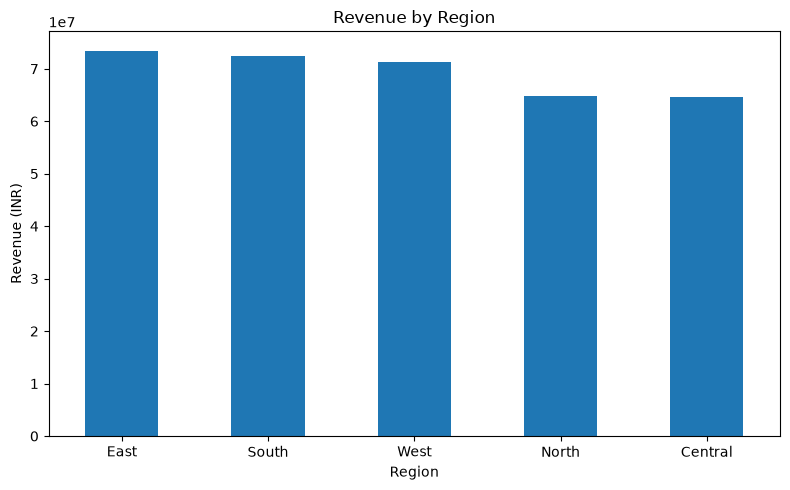

In [223]:
plt.figure(figsize=(8, 5))

sales_by_region.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [224]:
finance["MonthYear"] = pd.to_datetime(
    finance["MonthYear"]
)

monthly_profit = (
    finance.groupby("MonthYear")["Profit_INR"]
    .sum()
    .sort_index()
)

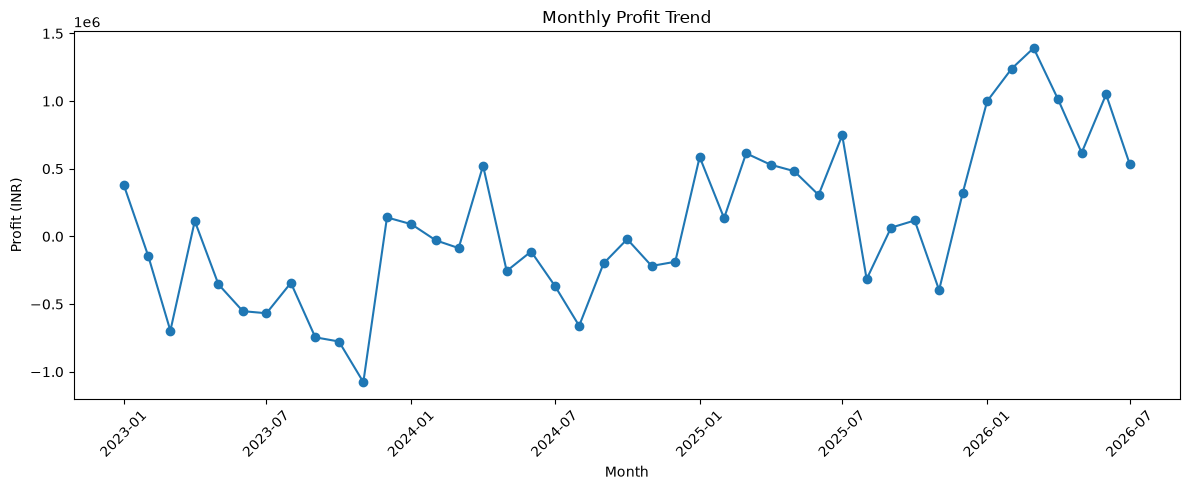

In [225]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_profit.index,
    monthly_profit.values,
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

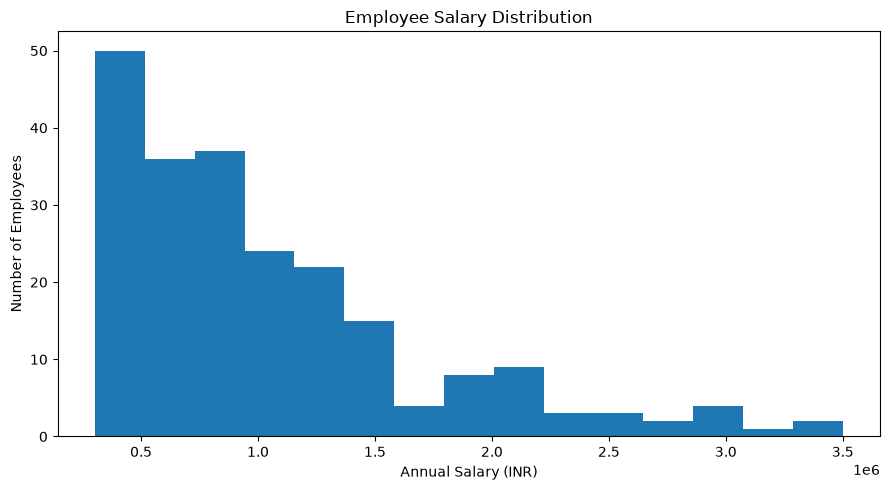

In [226]:
plt.figure(figsize=(9, 5))

plt.hist(
    employees["AnnualSalary_INR"].dropna(),
    bins=15
)

plt.title("Employee Salary Distribution")
plt.xlabel("Annual Salary (INR)")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

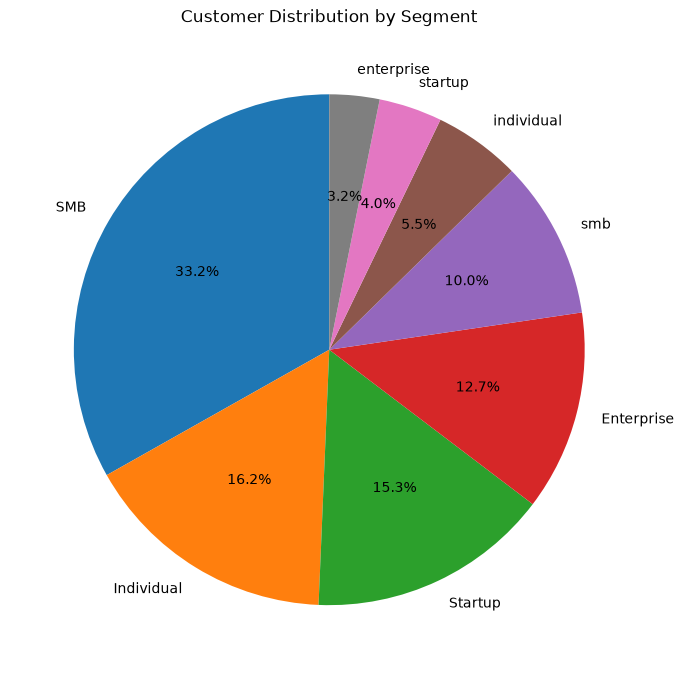

In [227]:
segment_counts = customers["Segment"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by Segment")
plt.tight_layout()
plt.show()

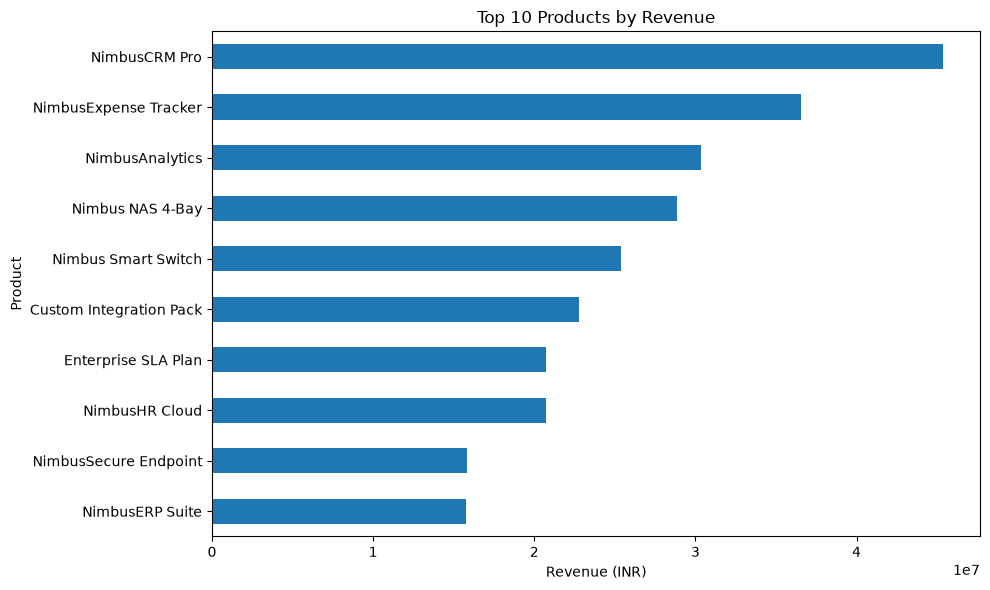

In [228]:
top_products = sales_by_product.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_products.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (INR)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

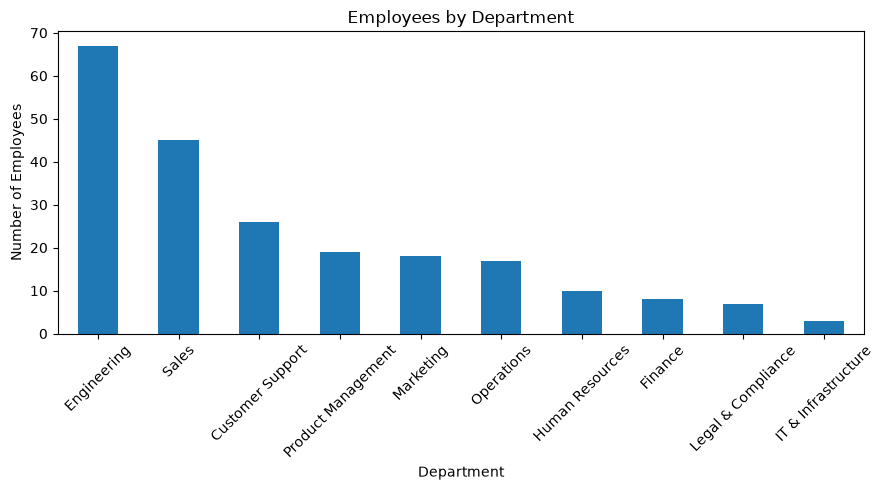

In [229]:
plt.figure(figsize=(9, 5))

employee_department.plot(kind="bar")

plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

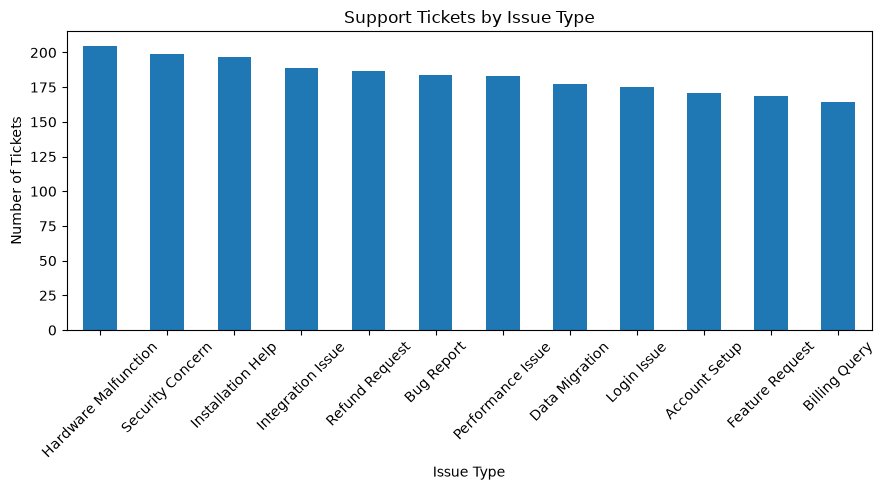

In [230]:
plt.figure(figsize=(9, 5))

tickets_by_issue.plot(kind="bar")

plt.title("Support Tickets by Issue Type")
plt.xlabel("Issue Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 10. Executive Business Dashboard

The executive dashboard summarizes the organization's overall performance.

It combines financial, sales, customer, employee, and operational metrics into a single visual overview.

The purpose is to allow management to quickly understand the current state of the organization and identify areas requiring attention.

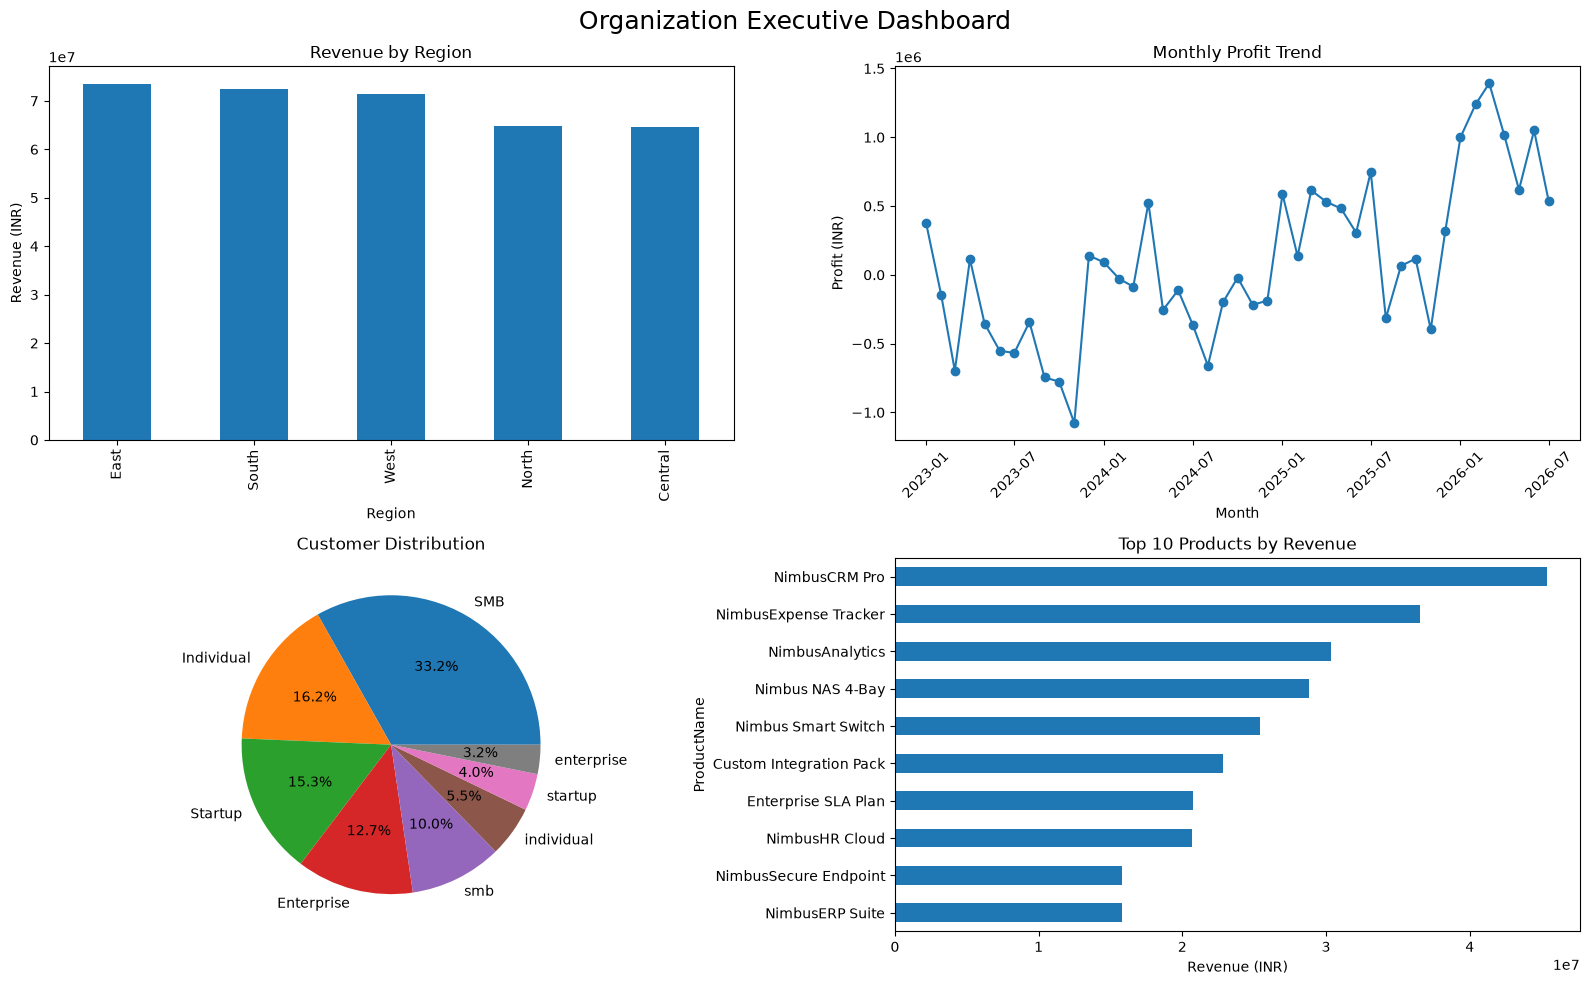

In [231]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Revenue by Region
sales_by_region.plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Revenue by Region")
axes[0, 0].set_xlabel("Region")
axes[0, 0].set_ylabel("Revenue (INR)")


# 2. Monthly Profit
axes[0, 1].plot(
    monthly_profit.index,
    monthly_profit.values,
    marker="o"
)

axes[0, 1].set_title("Monthly Profit Trend")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Profit (INR)")
axes[0, 1].tick_params(axis="x", rotation=45)


# 3. Customer Segments
axes[1, 0].pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct="%1.1f%%"
)

axes[1, 0].set_title("Customer Distribution")


# 4. Top Products
top_products.plot(
    kind="barh",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Top 10 Products by Revenue")
axes[1, 1].set_xlabel("Revenue (INR)")

plt.suptitle(
    "Organization Executive Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [232]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Orders",
        "Average Order Value",
        "Total Customers",
        "Active Employees",
        "Total Profit",
        "Marketing Budget",
        "Average Attendance",
        "Customer Satisfaction"
    ],
    "Value": [
        total_sales,
        total_orders,
        average_order_value,
        total_customers,
        active_employees,
        total_profit,
        total_marketing_spend,
        average_attendance,
        average_satisfaction
    ]
})

kpi_summary

,KPI,Value
0,Total Sales,3.468946e+08
1,Total Orders,6.000000e+03
2,Average Order Value,5.781577e+04
3,Total Customers,6.000000e+02
4,Active Employees,1.830000e+02
5,Total Profit,3.892687e+06
6,Marketing Budget,5.256513e+07
7,Average Attendance,9.449020e+01
8,Customer Satisfaction,4.011898e+00


# 11. Business Insights and Recommendations

## Sales

Revenue should be compared across regions and products to identify the strongest and weakest markets.

## Finance

Revenue, expenses, and profit trends help management understand the organization's financial health.

## Customers

Customer segments and regional distribution help identify the organization's most valuable customer groups.

## Employees

Employee distribution, salary, performance, and attendance provide insight into workforce structure and productivity.

## Marketing

Campaign budget, leads, and conversion rate help determine which marketing channels are generating better results.

## Customer Support

Ticket volume, resolution time, and satisfaction scores help identify customer service problems.

## Projects

Project status and budget-versus-actual cost analysis help management identify delayed or over-budget projects.

## Recommendations

1. Focus on high-performing regions and products.
2. Investigate regions or products with low revenue.
3. Optimize marketing channels based on lead generation and conversion.
4. Monitor employee attendance and performance.
5. Investigate projects with delays or high cost overruns.
6. Improve customer support for issue categories with high ticket volume.
7. Monitor monthly profit trends and control unnecessary expenses.